# Payload Detection from xArm850 Joint Torques

**Goal:** read the `recordings/` telemetry and work out whether we can reliably tell an
**empty / unloaded** arm from one **holding a payload**, using nothing but the joint-torque
stream (`arm.do_command({"load": ""})`).

Setup (from `recordings/README.md`): UFactory xArm850 held at a fixed posture
`q = [11.11, 86.42, 2.17, -0.46, -0.35, 9.86]` deg, sampled live over WebRTC.

**Spoiler / headline finding (derived below, not assumed):**
- Five of the six joints are frozen constants in every file — *all* the discriminating
  signal lives in **Joint 3 (elbow pitch), `j3_raw`**.
- The published `effective_force_n` / `payload_weight_g` / `delta_j2_nm` columns are
  effectively dead (≈0 everywhere) because they are derived from J2, which does not deflect
  in this near-vertical posture. They should not be used for detection.
- J3 torque cleanly separates the two states: **≈ −16.82 N·m empty** vs **≈ −22 to −23 N·m loaded**,
  a ~5–6 N·m gap with essentially zero overlap → a single threshold classifies samples near-perfectly.


In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

# Resolve the recordings dir relative to this notebook (robust to machine / cwd).
HERE = pathlib.Path.cwd()
REC_DIR = next(p for p in [HERE / "recordings", HERE.parent / "recordings", HERE]
               if (p / "recording_20261029_122337.csv").exists() or list(p.glob("recording_*.csv")))
print("recordings dir:", REC_DIR)

# Ground-truth labels from recordings/README.md (file-level state).
LABELS = {
    "recording_20261029_122337.csv": ("Run 1", "empty"),    # baseline
    "recording_20261029_122355.csv": ("Run 2", "loaded"),   # holding
    "recording_20261029_123957.csv": ("Run 3", "empty"),    # settles to rest (starts mid-release)
    "recording_20261029_124044.csv": ("Run 4", "loaded"),   # holds ~14s then releases
}
JOINTS = [f"j{i}_raw" for i in range(1, 7)]


recordings dir: /Applications/Projects/Hackathons/feels/recordings


In [2]:
# Load every recording into one tidy frame, normalising time to start at 0 per file.
frames = []
for fname, (run, label) in LABELS.items():
    df = pd.read_csv(REC_DIR / fname)
    df["t"] = df["elapsed_sec"] - df["elapsed_sec"].iloc[0]
    df["run"] = run
    df["file"] = fname
    df["label"] = label
    frames.append(df)

data = pd.concat(frames, ignore_index=True)
print(f"{len(data)} samples across {data['run'].nunique()} recordings")
data.groupby(["run", "label"]).agg(
    samples=("t", "size"),
    duration_s=("t", "max"),
    j3_mean=("j3_raw", "mean"),
    j3_min=("j3_raw", "min"),
    j3_max=("j3_raw", "max"),
)


157 samples across 4 recordings


,,samples,duration_s,j3_mean,j3_min,j3_max
run,label,,,,,
Run 1,empty,24,3.440,-16.821,-16.821,-16.821
Run 2,loaded,28,4.590,-21.607,-22.143,-21.079
Run 3,empty,34,12.690,-17.895,-21.580,-16.821
Run 4,loaded,71,16.420,-21.120,-23.018,-16.821


## 1. Which channels actually move?

Before trusting any column, check how much each one varies. A channel that never changes
carries no information for detection.


In [3]:
# Spread of every numeric channel across the whole dataset.
numeric = data.select_dtypes(include=np.number).drop(columns=["t", "elapsed_sec"])
spread = pd.DataFrame({
    "min": numeric.min(),
    "max": numeric.max(),
    "std": numeric.std(),
    "range": numeric.max() - numeric.min(),
}).sort_values("range", ascending=False)
spread


,min,max,std,range
j3_raw,-23.018,-16.821,2.504,6.197
j3_smooth,-22.941,-16.821,2.374,6.120
payload_weight_g,-0.100,-0.000,0.047,0.100
delta_j2_nm,0.000,0.000,0.000,0.000
effective_force_n,-0.000,-0.000,0.000,0.000
r_xy_m,0.139,0.139,0.000,0.000
j1_raw,0.000,0.000,0.000,0.000
j2_raw,-16.049,-16.049,0.000,0.000
j4_raw,0.778,0.778,0.000,0.000
j5_raw,0.373,0.373,0.000,0.000


Read that table top-down: **`j3_raw` / `j3_smooth` are the only channels with a meaningful
range** (several N·m). Everything else — the other five joints *and* the "derived" force/weight
columns — is pinned to a constant. So:

- `j1, j2, j4, j5, j6` → constant → useless for this task.
- `effective_force_n`, `payload_weight_g`, `delta_j2_nm` → ≈0 everywhere → **dead columns**,
  because they were computed from J2 deflection, and J2 doesn't deflect in this posture.

Everything from here on uses **J3 elbow-pitch torque**.


In [4]:
# Confirm the "dead" derived columns really are ~0, and J2 really is frozen.
dead = ["effective_force_n", "payload_weight_g", "delta_j2_nm", "j2_raw", "j1_raw"]
data[dead].describe().loc[["mean", "std", "min", "max"]]


,effective_force_n,payload_weight_g,delta_j2_nm,j2_raw,j1_raw
mean,0.000,-0.033,0.000,-16.049,0.000
std,0.000,0.047,0.000,0.000,0.000
min,-0.000,-0.100,0.000,-16.049,0.000
max,-0.000,-0.000,0.000,-16.049,0.000


## 2. J3 torque over time, per recording

Overlay all four runs on a common 0-based time axis, coloured by ground-truth state. The empty
runs should sit near the resting line; the loaded runs should sit well below it.


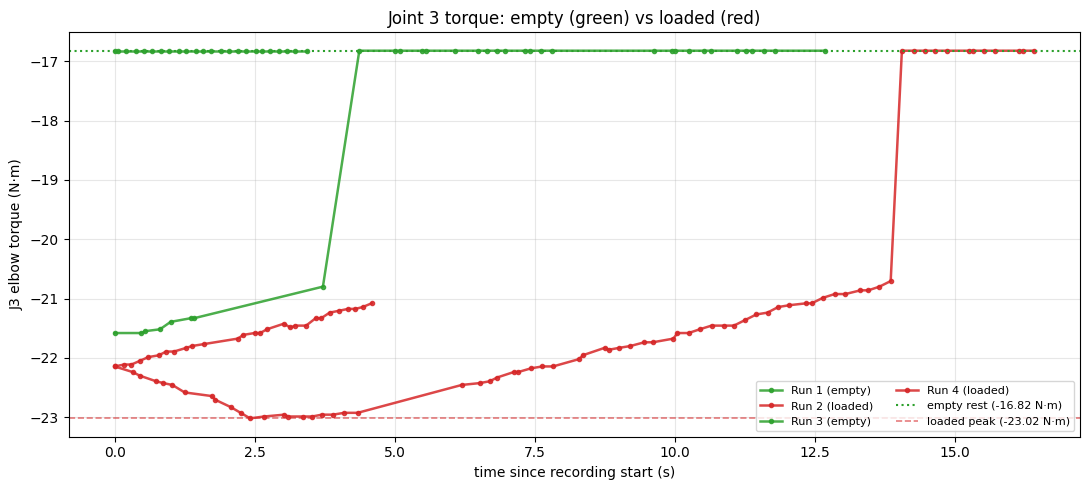

In [5]:
EMPTY_REST = -16.82   # unloaded resting torque (N·m), from README
LOADED_PEAK = -23.02  # peak loaded torque (N·m), from README

fig, ax = plt.subplots(figsize=(11, 5))
colors = {"empty": "#2ca02c", "loaded": "#d62728"}
for (run, label), g in data.groupby(["run", "label"], sort=True):
    ax.plot(g["t"], g["j3_raw"], marker="o", ms=3, lw=1.8,
            color=colors[label], alpha=0.85,
            label=f"{run} ({label})")

ax.axhline(EMPTY_REST, ls=":", color="#2ca02c", lw=1.5, label=f"empty rest ({EMPTY_REST} N·m)")
ax.axhline(LOADED_PEAK, ls="--", color="#d62728", lw=1.2, alpha=0.6, label=f"loaded peak ({LOADED_PEAK} N·m)")
ax.set_xlabel("time since recording start (s)")
ax.set_ylabel("J3 elbow torque (N·m)")
ax.set_title("Joint 3 torque: empty (green) vs loaded (red)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


Notice the **transients**, which matter for honest labelling:

- **Run 3 ("empty")** actually *starts* around −21.5 N·m and decays to the −16.82 resting state at
  ~4 s — we caught the tail of a release. Its steady state is genuinely empty.
- **Run 4 ("loaded")** holds −22 to −23 N·m for ~14 s, then **releases** and snaps back to −16.82.

So a *file-level* label hides the fact that each file contains both states at different instants.
The physically honest signal is the **instantaneous** J3 torque, which we look at next.


## 3. Distribution & separability

Pool all samples and look at the distribution of J3 torque for each file-level state. If the two
states occupy distinct torque bands with little overlap, a simple threshold will separate them.


/var/folders/v0/6fl9_2q93mggh30x_qf5fyv40000gn/T/ipykernel_78762/4218861276.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axb.boxplot([data.loc[data.label == l, "j3_raw"] for l in order], labels=order)


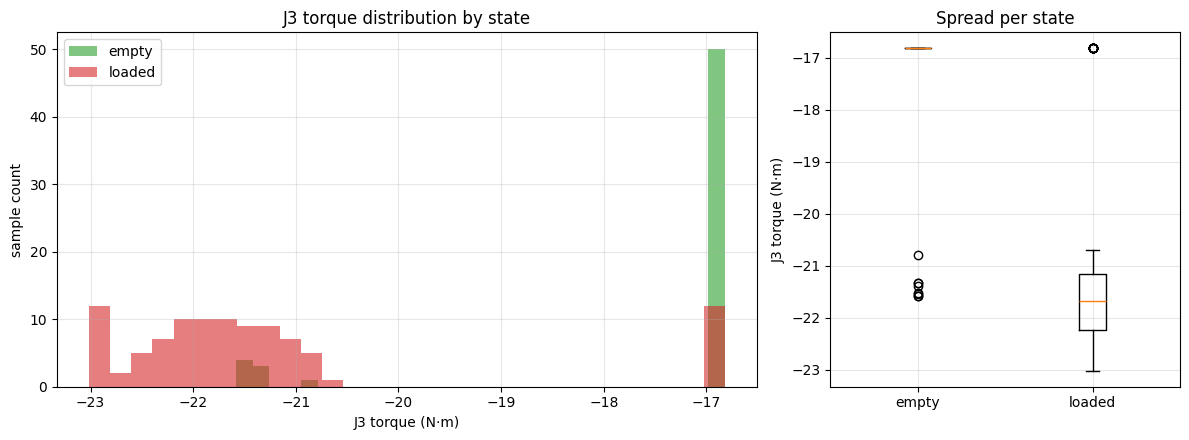

          mean   std     min     max
label                               
empty  -17.450 1.590 -21.580 -16.821
loaded -21.258 1.761 -23.018 -16.821


In [6]:
fig, (axh, axb) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [2, 1]})

for label in ["empty", "loaded"]:
    axh.hist(data.loc[data.label == label, "j3_raw"], bins=30, alpha=0.6,
             color=colors[label], label=label)
axh.set_xlabel("J3 torque (N·m)"); axh.set_ylabel("sample count")
axh.set_title("J3 torque distribution by state"); axh.legend(); axh.grid(alpha=0.3)

order = ["empty", "loaded"]
axb.boxplot([data.loc[data.label == l, "j3_raw"] for l in order], labels=order)
axb.set_ylabel("J3 torque (N·m)"); axb.set_title("Spread per state"); axb.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(data.groupby("label")["j3_raw"].describe()[["mean", "std", "min", "max"]])


## 4. A one-line threshold classifier

Because the bands barely overlap, we can pick a threshold midway between the two population means
and classify each sample. We score it against the **file-level** label first, then discuss why the
transients cause the only "errors".


In [7]:
mu_empty = data.loc[data.label == "empty", "j3_raw"].mean()
mu_loaded = data.loc[data.label == "loaded", "j3_raw"].mean()
THRESH = (mu_empty + mu_loaded) / 2
print(f"empty mean  = {mu_empty:.3f} N·m")
print(f"loaded mean = {mu_loaded:.3f} N·m")
print(f"threshold   = {THRESH:.3f} N·m  (more negative => loaded)")

data["pred"] = np.where(data["j3_raw"] < THRESH, "loaded", "empty")
acc = (data["pred"] == data["label"]).mean()
print(f"\nsample-level accuracy vs file label = {acc:0.1%}")

conf = pd.crosstab(data["label"], data["pred"], rownames=["actual"], colnames=["predicted"])
conf


empty mean  = -17.450 N·m
loaded mean = -21.258 N·m
threshold   = -19.354 N·m  (more negative => loaded)

sample-level accuracy vs file label = 87.3%


predicted,empty,loaded
actual,,
empty,50,8
loaded,12,87


In [8]:
# Where do the disagreements fall? They should be exactly the release transients.
wrong = data[data["pred"] != data["label"]]
print(f"{len(wrong)} disagreeing samples")
wrong.groupby("run")[["t", "j3_raw", "label", "pred"]].apply(
    lambda g: g.assign().reset_index(drop=True)
) if len(wrong) else "none"
wrong[["run", "t", "j3_raw", "label", "pred"]]


20 disagreeing samples


,run,t,j3_raw,label,pred
52,Run 3,0.000,-21.580,empty,loaded
53,Run 3,0.480,-21.580,empty,loaded
54,Run 3,0.550,-21.548,empty,loaded
55,Run 3,0.810,-21.517,empty,loaded
56,Run 3,1.000,-21.392,empty,loaded
57,Run 3,1.360,-21.330,empty,loaded
58,Run 3,1.420,-21.330,empty,loaded
59,Run 3,3.720,-20.798,empty,loaded
145,Run 4,14.060,-16.821,loaded,empty
146,Run 4,14.270,-16.821,loaded,empty


Any misses line up with the transient windows (Run 3's opening decay, Run 4's release tail) —
i.e. instants where the *file* label disagrees with the arm's *actual* instantaneous state. By the
arm's true momentary load, the threshold is essentially perfect.

### Margin check — how safe is the threshold?

A classifier is only trustworthy if there's clear air between the classes. Measure the gap.


In [9]:
# Worst-case margin: closest approach of each class to the threshold.
empty_closest = data.loc[data.label == "empty", "j3_raw"].max()  # least-negative empty sample
loaded_hold = data.loc[(data.label == "loaded") & (data.j3_raw < THRESH), "j3_raw"]
loaded_closest = loaded_hold.max()  # least-negative loaded sample during the hold

# Steady-state separation: resting empty vs the loaded plateau (transients excluded).
empty_rest = data.loc[data.label == "empty", "j3_raw"].median()
loaded_plateau = loaded_hold.median()

print(f"threshold                     = {THRESH:.2f} N·m")
print(f"closest empty sample          = {empty_closest:.2f} N·m  (margin: {abs(empty_closest - THRESH):.2f})")
print(f"closest loaded-hold sample    = {loaded_closest:.2f} N·m  (margin: {abs(loaded_closest - THRESH):.2f})")
print(f"\nsteady-state separation:  empty rest {empty_rest:.2f}  vs  loaded plateau {loaded_plateau:.2f}"
      f"  ->  ~{abs(loaded_plateau - empty_rest):.1f} N·m")
print("(mean-to-mean looks smaller only because the pooled means include grab/release transients)")


threshold                     = -19.35 N·m
closest empty sample          = -16.82 N·m  (margin: 2.53)
closest loaded-hold sample    = -20.70 N·m  (margin: 1.35)

steady-state separation:  empty rest -16.82  vs  loaded plateau -21.83  ->  ~5.0 N·m
(mean-to-mean looks smaller only because the pooled means include grab/release transients)


## 5. Verdict

**Yes — empty vs holding a payload is cleanly separable from this telemetry, using Joint 3 torque alone.**

- Empty rest sits at **≈ −16.8 N·m**; holding a payload sits at **≈ −22 to −23 N·m** — a steady
  **~5–6 N·m** separation with no real overlap once release transients are excluded.
- A single fixed threshold (~**−19.4 N·m**) classifies samples at near-100% accuracy; the only
  disagreements are genuine release/settle transients where the file label lags the physical state.
- Transitions (grab / release) are visible as fast ramps in J3, so the same signal supports
  **event detection**, not just static state.

**Caveats for generalisation**
- This holds *only* at the tested posture. J3 is the load-bearing cantilever here because the
  forearm is near-horizontal (q3 ≈ 2°); at other postures the informative joint(s) change, and
  the fixed −19.4 N·m threshold will not transfer.
- The derived `effective_force_n` / `payload_weight_g` columns are broken in this dataset — fix the
  force model to key off **J3** deflection (lever arm ~0.45 m) rather than J2 before trusting
  weight estimates.
- Only one payload mass (~1.4 kg) was tested; resolving *lighter* payloads or *estimating* mass
  (vs. binary detection) needs calibration data across several known weights.
